# SPSA, SGD, and Adam: optimizer comparison

## 1. Question and experimental controls

How does forward-only SPSA compare with backpropagation-based SGD and Adam on
the same small classification task? Run all cells from the project folder.

All methods share a fixed 60/20/20 moons split, train-only standardization, a
2 → 8 → 2 tanh network, target encoding, loss, batch size, and epoch budget.
Within each trial they share initial weights and minibatch order. Three trials
vary initialization and training randomness while keeping the data split fixed.
Learning rates are illustrative fixed choices, not an exhaustive tuning study.

SPSA uses bottom-up weight/bias blocks, five updates per block. SGD and Adam
make one gradient update per batch. Equal epochs therefore do **not** mean equal
compute. Forward-objective calls and gradient calls are reported separately.

In [1]:
from pathlib import Path
import platform
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import accuracy_score
from neural_network import DenseTanhNetwork
from training import prepare_moons_data, train_spsa, train_gradient_optimizer
from evaluation import plot_loss_curves, save_checkpoint, predict_checkpoint, save_experiment

data = prepare_moons_data(seed=42)
network = DenseTanhNetwork([2, 8, 2])
configuration = {
    'dataset': 'moons', 'data_seed': 42, 'n_samples': 600, 'noise': 0.2,
    'split': [360, 120, 120], 'layer_sizes': [2, 8, 2], 'slope': 1.0,
    'epochs': 40, 'batch_size': 64, 'initialization_seeds': [0, 1, 2],
    'spsa': {'learning_rate': 0.03, 'perturbation': 0.1, 'inner_steps': 5,
             'order': 'bottom_up', 'split_weights_biases': True, 'alpha': 1.0, 'gamma': 1/6},
    'sgd_learning_rate': 0.03, 'adam_learning_rate': 0.01,
    'adam_beta1': 0.9, 'adam_beta2': 0.999, 'adam_epsilon': 1e-8,
    'python': platform.python_version(), 'numpy': np.__version__, 'sklearn': sklearn.__version__,
}
print('Parameters:', network.n_parameters)
print('Train / validation / test:', configuration['split'])

Parameters: 42
Train / validation / test: [360, 120, 120]


## 2. Train all three optimizers

The SPSA implementation only calls the loss. Baseline derivatives are calculated
explicitly in `loss_and_gradient` so the role of backpropagation is visible.
Adam maintains first and second moments and corrects their initial bias.
All histories include epoch zero. Elapsed time includes loss monitoring and
Python overhead; it measures this implementation on this machine.

In [2]:
records = []
all_histories = {name: [] for name in ('SPSA', 'SGD', 'Adam')}
for seed in configuration['initialization_seeds']:
    initial = network.initialize(seed)
    shared = dict(epochs=configuration['epochs'], batch_size=configuration['batch_size'],
                  shuffle_seed=2000 + seed,
                  validation_data=(data['X_validation'], data['Y_validation']), verbose=False)
    runs = {
        'SPSA': train_spsa(network, initial, data['X_train'], data['Y_train'],
                           seed=1000 + seed, **configuration['spsa'], **shared),
        'SGD': train_gradient_optimizer(network, initial, data['X_train'], data['Y_train'],
                                        optimizer='sgd', learning_rate=configuration['sgd_learning_rate'], **shared),
        'Adam': train_gradient_optimizer(network, initial, data['X_train'], data['Y_train'],
                                         optimizer='adam', learning_rate=configuration['adam_learning_rate'], **shared),
    }
    for name, (parameters, history) in runs.items():
        predictions = network.predict(parameters, data['X_test'])
        record = {
            'optimizer': name, 'seed': seed, 'shuffle_seed': 2000 + seed,
            'perturbation_seed': 1000 + seed if name == 'SPSA' else None,
            'training_loss': history['training_loss'][-1],
            'validation_loss': history['validation_loss'][-1],
            'test_accuracy': float(accuracy_score(data['y_test'], predictions)),
            'seconds': history['elapsed_seconds'][-1],
            'objective_evaluations': history['objective_evaluations'][-1],
            'gradient_evaluations': history['gradient_evaluations'][-1],
            'monitoring_evaluations': history['monitoring_evaluations'][-1],
        }
        path = f"outputs/checkpoints/moons_{name.lower()}_seed{seed}.npz"
        save_checkpoint(path, network, parameters, {'configuration': configuration, 'result': record},
                        mean=data['mean'], scale=data['scale'])
        raw_test = data['X_test'] * data['scale'] + data['mean']
        np.testing.assert_array_equal(predict_checkpoint(path, raw_test), predictions)
        records.append(record)
        all_histories[name].append(history)
    print(f'Trial {seed + 1} finished; checkpoint predictions verified.')

Trial 1 finished; checkpoint predictions verified.
Trial 2 finished; checkpoint predictions verified.
Trial 3 finished; checkpoint predictions verified.


## 3. Loss curves and computational work

Solid curves below are trial means; bands show ± one standard deviation across
the three training trials. They are not confidence intervals. A noisier SPSA
curve is possible because each direction is estimated from random perturbations.
Training and validation loss can behave differently; inspect both.

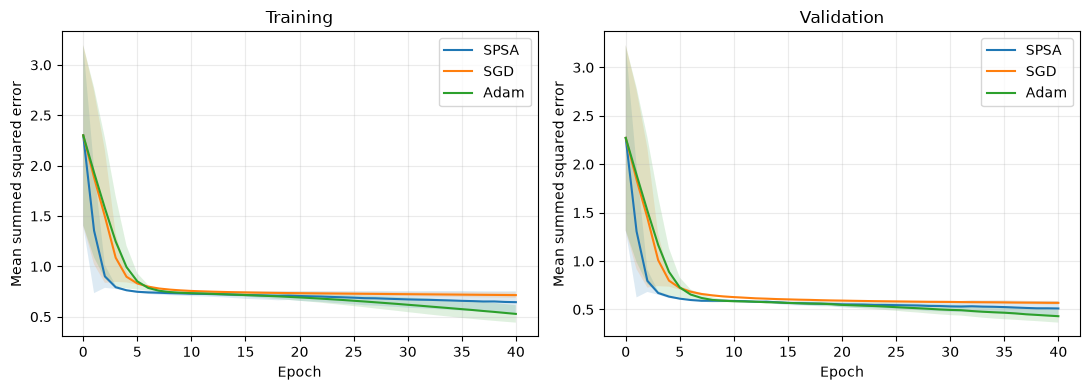

Method     Train loss     Val loss    Test accuracy    Seconds
SPSA           0.6446       0.5105     88.9% ± 2.1%       0.44
  Per trial: 9600 SPSA objective calls; 0 baseline gradient calls; 82 monitoring calls
SGD            0.7147       0.5683     86.9% ± 1.4%       0.02
  Per trial: 0 SPSA objective calls; 240 baseline gradient calls; 82 monitoring calls
Adam           0.5282       0.4307     91.7% ± 1.2%       0.03
  Per trial: 0 SPSA objective calls; 240 baseline gradient calls; 82 monitoring calls


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, histories in all_histories.items():
    epochs = histories[0]['epoch']
    for axis, key in zip(axes, ('training_loss', 'validation_loss')):
        values = np.array([history[key] for history in histories])
        average, spread = values.mean(axis=0), values.std(axis=0)
        axis.plot(epochs, average, label=name)
        axis.fill_between(epochs, average - spread, average + spread, alpha=0.15)
for axis, title in zip(axes, ('Training', 'Validation')):
    axis.set(title=title, xlabel='Epoch', ylabel='Mean summed squared error')
    axis.legend()
    axis.grid(alpha=0.25)
fig.tight_layout()
Path('outputs/figures').mkdir(parents=True, exist_ok=True)
fig.savefig('outputs/figures/optimizer_comparison.png', dpi=160)
plt.show()

print(f"{'Method':<8} {'Train loss':>12} {'Val loss':>12} {'Test accuracy':>16} {'Seconds':>10}")
for name in all_histories:
    rows = [r for r in records if r['optimizer'] == name]
    accuracy = np.array([r['test_accuracy'] for r in rows])
    print(f"{name:<8} {np.mean([r['training_loss'] for r in rows]):>12.4f} "
          f"{np.mean([r['validation_loss'] for r in rows]):>12.4f} "
          f"{accuracy.mean():>9.1%} ± {accuracy.std():.1%} "
          f"{np.mean([r['seconds'] for r in rows]):>10.2f}")
    print('  Per trial:', rows[0]['objective_evaluations'], 'SPSA objective calls;',
          rows[0]['gradient_evaluations'], 'baseline gradient calls;',
          rows[0]['monitoring_evaluations'], 'monitoring calls')

## 4. Save the experiment and interpret the measured results

The test split never participates in training or model selection. We report the
final epoch for every trial, with no best-test-seed selection. Three seeds offer
a small indication of sensitivity; they do not establish universal rankings.

For SPSA, the update-call budget is:
`epochs × ceil(training_examples / batch_size) × blocks × inner_steps × 2`.
For SGD/Adam, gradient calls equal `epochs × batches`. Monitoring is additional.
Different call types must not be treated as equal computational units.

In [4]:
Path('outputs/experiments').mkdir(parents=True, exist_ok=True)
np.savez_compressed('outputs/experiments/moons_split.npz', **data)
save_experiment('outputs/experiments/moons_optimizer_comparison.json',
                {'configuration': configuration, 'results': records, 'histories': all_histories})
for name, histories in all_histories.items():
    initial_loss = np.mean([h['training_loss'][0] for h in histories])
    final_loss = np.mean([h['training_loss'][-1] for h in histories])
    print(f'{name}: mean training loss {initial_loss:.4f} → {final_loss:.4f}')
best = min(all_histories, key=lambda name: np.mean([h['validation_loss'][-1] for h in all_histories[name]]))
print(f'Lowest mean final validation loss in this run: {best}.')
print('Interpret this together with accuracy, trial variation, runtime, and evaluation counts.')

SPSA: mean training loss 2.3006 → 0.6446
SGD: mean training loss 2.3006 → 0.7147
Adam: mean training loss 2.3006 → 0.5282
Lowest mean final validation loss in this run: Adam.
Interpret this together with accuracy, trial variation, runtime, and evaluation counts.


## 5. Relationship to the research and earlier experiments

- The scheduled SPSA equations and block-wise updates follow Algorithms 1 and 2
  of Wulff, Schuecker and Bauckhage (2018).
- This small 2 → 8 → 2 moons experiment is an illustration, not the paper's exact
  architecture or experimental reproduction. The optional MNIST architecture
  remains 784 → 196 → 10 (155,830 weights and biases).
- Our loss averages over examples; the paper's equation (9) sums them. Our MNIST
  targets retain the earlier notebook's -1/+1 encoding, while the paper's MNIST
  description specifies 0/1 one-hot targets.
- [SimpleArt/spsa](https://github.com/SimpleArt/spsa) adds automatic tuning and
  adaptive momentum. It is retained as a reference; these new experiments use
  our transparent scheduled implementation, not that adaptive optimizer.
- Historical MNIST measurements remain in `outputs/phase4` and `outputs/phase5`;
  none of the new plots or results are presented as regenerations of those runs.

Paper: [SPSA for Layer-Wise Training of Deep Networks](https://doi.org/10.1007/978-3-030-01424-7_55).